# Spectral-Spatial RF Pulses

**Part:** J – Advanced & fun topics · **Reading time:** ~45 min · **Pass 1 overview:** [From signal to image](../pass1_big_picture/P1.3_From_Signal_to_Image.ipynb) · **Prerequisites:** [E2 Slice selection](E2_Slice_Selection.ipynb), [E3 RF pulse design](E3_RF_Pulse_Design.ipynb), [J1 Excitation k-space](J1_Excitation_K-space.ipynb) · **Refreshers you may want:** [Fourier properties](../refreshers/RM4_Fourier_Properties.ipynb), [Fourier pairs & sampling](../refreshers/RM5_Fourier_Pairs_and_Sampling.ipynb)

Spectral-spatial RF pulses aim to provide both
- **spectral selection**, typically to excite only protons in water molecules and not protons in lipids (fat), and
- **spatial selection**, for slice-selective imaging.

These pulses are particularly common in fMRI and diffusion imaging with echo-planar imaging (EPI), where they eliminate chemical-shift displacement artifacts. They are also used for water and/or fat suppression in MR spectroscopy.

**Why this chapter matters.** It is the clearest example of how far the "excitation k-space" view of [J1](J1_Excitation_K-space.ipynb) takes you. By treating *time* as a second k-space axis, a 2D excitation in (frequency, position) becomes a 2D filter design problem. The same idea underlies multi-band and parallel-transmit pulses.

## Learning goals

1. Describe how images are formed
    * Understand how spectral-spatial RF pulses work
2. Identify artifacts and how to mitigate them
    * Determine when using spectral-spatial RF pulses would help remove chemical-shift-related artifacts
3. *(added)* Explain the two k-space axes of a spectral-spatial pulse: $k_z$ (from the oscillating gradient) and $k_f$ (from time itself).
4. *(added)* Derive why the spectral profile repeats every $1/\Delta T$ Hz, and choose the sub-pulse spacing $\Delta T$ for a given field strength.
5. *(added)* Build a spectral-spatial pulse in Python (spectral envelope × VERSE'd spatial sub-pulses) and simulate its 2D profile.

## Symbols used in this chapter

| Symbol | Meaning (plain words) | SI unit | Typical value / remark |
|---|---|---|---|
| $z$ | position along the slice direction | m | |
| $f$ (or $\Delta f$) | off-resonance frequency of a spin relative to the RF centre frequency | Hz | water 0, fat ≈ −3.5 ppm |
| $\Delta f_{fat}$ | fat–water frequency difference $= -3.5\,\text{ppm}\cdot\bar\gamma B_0$ | Hz | −224 Hz @1.5 T, −447 Hz @3 T |
| $b_1(t)$ | complex RF envelope (rotating frame) | T | µT |
| $G_z(t)$ | slice gradient waveform (oscillating, bipolar) | T/m | ~10–20 mT/m here |
| $T$ | total pulse duration | s | 20 ms (original example) |
| $N_{spec}$ | number of spatial sub-pulses = number of samples of the spectral envelope | – | 10 |
| $\Delta T = T/N_{spec}$ | duration of one gradient lobe = spacing of the sub-pulses | s | 2 ms |
| $\Delta t$ | RF/gradient raster time | s | 10 µs |
| $TBW$ | time–bandwidth product of the **spectral** envelope | – | 3 |
| $SBW$ | time–bandwidth product of the **spatial** sub-pulse | – | 6 |
| $\Delta z$ | slice thickness (spatial resolution of the design) | m | 5 mm |
| $k_z(t) = -\bar\gamma\int_t^T G_z(\tau)\,d\tau$ | spatial excitation k-space coordinate | m⁻¹ | |
| $k_f(t) = t - T$ | spectral excitation k-space coordinate (time remaining until the end, negative) | s | |
| $h(f,z)$, $h_f$, $h_z$ | 2D target profile and its separable spectral and spatial factors | – | |
| $H(k_f,k_z)$, $H_f$, $H_z$ | their Fourier transforms (the "RF energy" in excitation k-space) | – | |
| $\theta$ | flip angle | rad | 45° here |
| $\alpha,\beta$ | Cayley–Klein parameters of the rotation (see [E3](E3_RF_Pulse_Design.ipynb)) | – | $M_{xy} = 2\alpha^*\beta$ for an excitation from $M_z=1$ |
| $G_{max}$, $SR$ | gradient amplitude and slew-rate limits | T/m, T/m/s | 40 mT/m, 150 T/m/s |

> **⚠️ Common confusion:** The original notebook's comments label `T = 20e-3` as "ms" and `dt = 10e-6` as "us". The *values* are in seconds (20 ms and 10 µs). Here everything is in SI units.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))   # make ../mri_tools.py importable
import numpy as np
import matplotlib.pyplot as plt
import mri_tools as mt
mt.setup_plots()
%matplotlib inline
from scipy.interpolate import CubicSpline

## 1. Two k-space axes: space *and* time

Recall from [J1](J1_Excitation_K-space.ipynb) the small-tip approximation. A spin at position $z$ with off-resonance $f$ ends up with

$$M_{xy}(z,f) \approx i\gamma M_0 \int_0^T b_1(t)\; e^{\,i2\pi\left(k_z(t)\,z \;+\; k_f(t)\,f\right)}\,dt$$

where $k_z(t) = -\bar\gamma\int_t^T G_z(\tau)\,d\tau$ and $k_f(t) = t-T$.

**In words:** RF energy deposited at time $t$ is "labelled" by two things: the gradient area *still to come* (which sets $k_z$) and the time *still to come* (which sets $k_f$). An off-resonant spin keeps precessing at $f$ for the remaining time $T-t$, so it picks up the phase $-2\pi f(T-t) = 2\pi f\,k_f$.

So $M_{xy}(z,f)$ is (approximately) the **2D Fourier transform** of the RF energy placed along the trajectory $(k_f(t), k_z(t))$. The gradient moves us along $k_z$; time moves us steadily along $k_f$. An **oscillating** gradient therefore sweeps $k_z$ back and forth while $k_f$ advances: an EPI-like zig-zag through 2D excitation k-space.

<details><summary><b>📐 Why does off-resonance act like an extra gradient?</b></summary>

In the rotating frame a spin with off-resonance $f$ precesses at angular frequency $2\pi f$, exactly as if it sat at a position where the gradient field adds $\Delta B_z = f/\bar\gamma$. A gradient $G_z$ produces $\Delta B_z = G_z z$. Formally, $f$ behaves like a "position" along a fictitious axis on which a *constant* gradient of 1 (in units of Hz per Hz) is always on. A constant gradient always on means k-space moves linearly with time, so $k_f = t - T$.

</details>

Let's plot the gradient and the resulting zig-zag trajectory (port of the original's first demo, in arbitrary units).

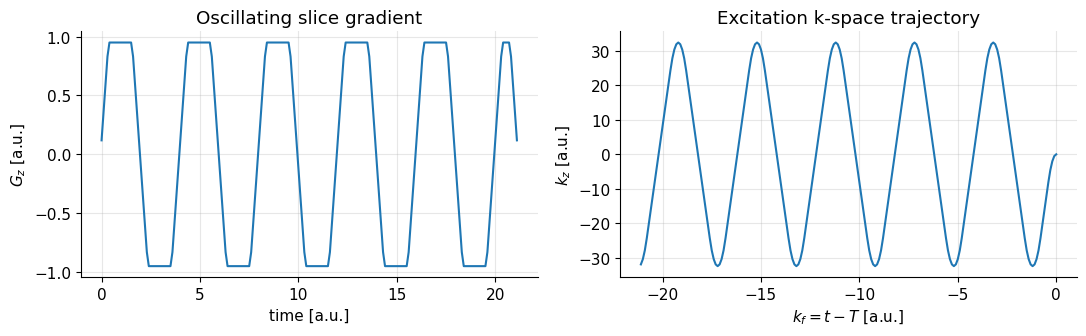

In [2]:
# Demo trajectory (arbitrary units, as in the original)
GB_demo, dt_demo = 42.58, 0.1
Nlobe_d, Nspec_d, Nramp_d = 20, 10, 4
ramp_d = (np.arange(Nramp_d) + 0.5) / Nramp_d
g1_d = np.concatenate([ramp_d, np.ones(Nlobe_d - 2 * Nramp_d), ramp_d[::-1]])
gamp_d = 0.95
g_d = np.concatenate([(1 if k % 2 else -1) * gamp_d * g1_d for k in range(1, Nspec_d + 1)])
Nrw_d = int(round((Nlobe_d - Nramp_d) / 2 + Nramp_d))
grw_d = np.concatenate([ramp_d, np.ones(Nrw_d - 2 * Nramp_d), ramp_d[::-1]])
g_d = np.concatenate([g_d, (1 if (Nspec_d + 1) % 2 else -1) * gamp_d * grw_d])   # rewinder: opposite to last lobe
t_d = np.arange(len(g_d)) * dt_demo
kz_d = GB_demo * dt_demo * (np.cumsum(g_d) - np.sum(g_d))      # = -gamma_bar * area still to come

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(t_d, g_d); ax[0].set_xlabel("time [a.u.]"); ax[0].set_ylabel("$G_z$ [a.u.]"); ax[0].set_title("Oscillating slice gradient")
ax[1].plot(t_d - t_d[-1], kz_d); ax[1].set_xlabel("$k_f = t - T$ [a.u.]"); ax[1].set_ylabel("$k_z$ [a.u.]")
ax[1].set_title("Excitation k-space trajectory"); plt.tight_layout(); plt.show()

**Interpretation.** Each gradient lobe sweeps $k_z$ from one edge to the other; consecutive lobes sweep in opposite directions. The short final **rewinder** lobe (half the area, opposite polarity to the last lobe) brings the trajectory back to $k_z = 0$ at the end, so that the spatial sub-pulses are centred and no residual phase across the slice remains (the same reason a normal slice-select pulse needs a rewinder, see [E2](E2_Slice_Selection.ipynb)).

## 2. Design strategy: a separable 2D filter

To design the pulse, approximate the target profile as **separable** in frequency and space:

$$h(f,z) = h_f(f)\,h_z(z) \qquad\Longleftrightarrow\qquad H(k_f,k_z) = H_f(k_f)\,H_z(k_z)$$

**In words:** "excite water but not fat" ($h_f$) times "excite only the slice" ($h_z$). Because a product in one domain stays a product in the Fourier domain (separability, [RM6](../refreshers/RM6_2D_Fourier_and_Images.ipynb)), the 2D k-space weighting is the product of two 1D pulses:

1. **Spectral pulse** $H_f(k_f)$: a short pulse with only $N_{spec}$ samples, one per gradient lobe. It sets the *envelope*.
2. **Spatial sub-pulse** $H_z(k_z)$: an ordinary slice-selective pulse that is played during each gradient lobe.
3. **Combine:** sub-pulse $k$ is the spatial pulse scaled by the $k$-th sample of the spectral pulse, played under alternating gradient lobes.

Below we need two small tools from [E3](E3_RF_Pulse_Design.ipynb): a least-squares FIR filter design for small-tip ("st") SLR pulses, and a Cayley–Klein (spinor) simulator that is much faster than stepping $\vec M$. We also need **VERSE** (variable-rate selective excitation), which resamples the RF so that it can be played during the gradient ramps.

In [3]:
def dinf(d1, d2):
    """Empirical 'D-infinity' factor relating ripples to transition width (Pauly et al. 1991)."""
    a1, a2, a3, a4, a5, a6 = 5.309e-3, 7.114e-2, -4.761e-1, -2.66e-3, -5.941e-1, -4.278e-1
    l1, l2 = np.log10(d1), np.log10(d2)
    return (a1 * l1**2 + a2 * l1 + a3) * l2 + (a4 * l1**2 + a5 * l1 + a6)

def dzrf_st(n, tbw, d1=0.01, d2=0.01, n_grid=4096):
    """Small-tip SLR pulse = linear-phase least-squares low-pass FIR filter with n taps (shape only, unit-free)."""
    w = dinf(d1, d2) / tbw                                  # fractional transition width
    fp, fs = (1 - w) * tbw / (2 * n), (1 + w) * tbw / (2 * n)   # band edges in cycles/sample
    f = np.linspace(0, 0.5, n_grid)
    bp, bs = f <= fp, f >= fs
    ff = np.concatenate([f[bp], f[bs]])
    d = np.concatenate([np.ones(bp.sum()), np.zeros(bs.sum())])
    wt = np.sqrt(np.concatenate([np.ones(bp.sum()), (d1 / d2) * np.ones(bs.sum())]))
    A = np.cos(2 * np.pi * np.outer(ff, np.arange(n) - (n - 1) / 2))
    h, *_ = np.linalg.lstsq(A * wt[:, None], d * wt, rcond=None)
    return h

def cayley_klein(rf, phase):
    """Spinor simulation. rf: (Nt,) complex rotation per step [rad] (= gamma*b1*dt);
    phase: (Nt, Ns) precession angle per step [rad] for each of Ns spins. Returns alpha, beta (Ns,)."""
    Ns = phase.shape[1]
    a = np.ones(Ns, complex); b = np.zeros(Ns, complex)
    for n in range(len(rf)):
        bx, by, bz = rf[n].real, rf[n].imag, phase[n]
        phi = np.sqrt(bx**2 + by**2 + bz**2)
        s = np.sin(phi / 2) / np.where(phi == 0, 1.0, phi)
        ar = np.cos(phi / 2) + 1j * bz * s
        br = 1j * (bx + 1j * by) * s
        a, b = ar * a - np.conj(br) * b, br * a + np.conj(ar) * b
    return a, b

def mxy_from_ck(a, b):
    """Transverse magnetization after an excitation from M = [0, 0, 1]."""
    return 2 * np.conj(a) * b

def verse(g, rf):
    """Resample a pulse designed for a constant gradient so it can be played under the waveform g (same total area).
    g: normalized gradient (Nt,), rf: pulse samples designed for constant gradient (Nt,)."""
    g = np.asarray(g, float); rf = np.asarray(rf, complex); m = len(rf)
    k = np.concatenate([[0], np.cumsum(g[:-1])]) + g / 2     # k-position of each sample (in samples)
    k = m * k / k.max()
    gn = m * g / g.sum()                                       # RF amplitude scales with local gradient
    x = np.arange(1, m + 1) - 0.5
    return gn * (CubicSpline(x, rf.real)(k) + 1j * CubicSpline(x, rf.imag)(k))

### 2.1 Design parameters

These are the original's parameters, converted to SI units:

In [4]:
GB = mt.GAMMA_BAR          # Hz/T
SR_max = 150.0             # T/m/s   (original: 15e3 G/cm/s)
G_max = 40e-3              # T/m     (original: 4 G/cm)
T = 20e-3                  # s, total duration
TBW = 3                    # spectral time-bandwidth product
SBW = 6                    # spatial time-bandwidth product
dz = 5e-3                  # m, slice thickness
N_spec = 10                # number of sub-pulses
DT = T / N_spec            # s, lobe duration = sub-pulse spacing (2 ms)
dt = 10e-6                 # s, raster time
flip = np.pi / 4           # 45 degrees

verse_frac = 0.8           # spatial sub-pulse uses 80 % of each lobe, the rest is ramp time
N_lobe = int(round(DT / dt))
N_spat = int(round(N_lobe * verse_frac))
N_wait = (N_lobe - N_spat) / 2

z = np.linspace(-8e-3, 8e-3, 161)     # m
df = np.linspace(-500, 500, 201)      # Hz
print(f"lobe: {N_lobe} samples = {DT*1e3:.1f} ms; spatial sub-pulse: {N_spat} samples; spectral samples: {N_spec}")

lobe: 200 samples = 2.0 ms; spatial sub-pulse: 160 samples; spectral samples: 10


### 2.2 Step 1: the spectral pulse (envelope)

The spectral pulse has only $N_{spec}=10$ samples, spaced $\Delta T = 2$ ms apart. Between samples the spins just precess, which the simulator models as precession by $2\pi f\,\Delta T$ per sample.

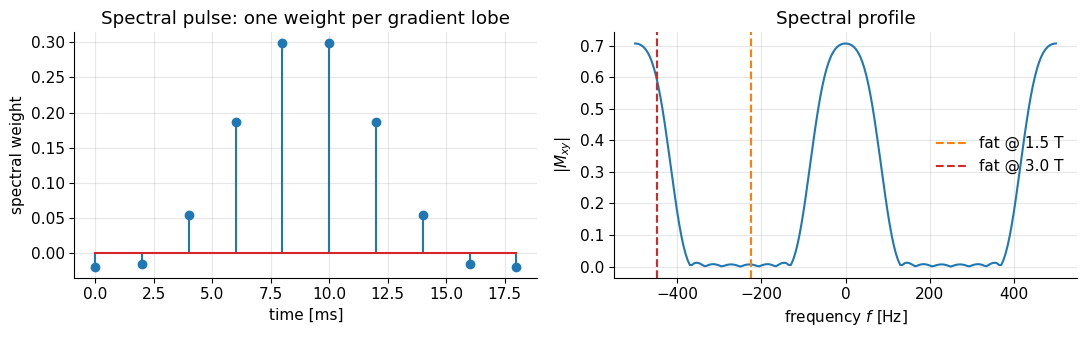

spectral passband FWHM ~ TBW/T = 150 Hz; profile repeats every 1/DT = 500 Hz


In [5]:
rf_spec = dzrf_st(N_spec, TBW)
# hard-pulse model: each spectral sample is an instantaneous RF rotation, followed by DT of free precession
rf_hp = np.zeros(2 * N_spec, complex); rf_hp[0::2] = rf_spec * (flip / rf_spec.sum())
ph_hp = np.zeros((2 * N_spec, len(df))); ph_hp[1::2] = 2 * np.pi * df * DT
a, b = cayley_klein(rf_hp, ph_hp)
mxy_f = mxy_from_ck(a, b)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].stem(np.arange(N_spec) * DT * 1e3, rf_spec); ax[0].set_xlabel("time [ms]"); ax[0].set_ylabel("spectral weight")
ax[0].set_title("Spectral pulse: one weight per gradient lobe")
ax[1].plot(df, np.abs(mxy_f))
for B0, c in ((1.5, "C1"), (3.0, "C3")):
    ax[1].axvline(mt.ppm_to_hz(mt.FAT_SHIFT_PPM, B0), color=c, ls="--", label=f"fat @ {B0} T")
ax[1].set_xlabel("frequency $f$ [Hz]"); ax[1].set_ylabel("$|M_{xy}|$"); ax[1].legend(); ax[1].set_title("Spectral profile")
plt.tight_layout(); plt.show()
print(f"spectral passband FWHM ~ TBW/T = {TBW/T:.0f} Hz; profile repeats every 1/DT = {1/DT:.0f} Hz")

**Interpretation.** Water (0 Hz) is excited and fat at 1.5 T (−224 Hz) lies in the stopband. Notice the **replicas** at ±500 Hz: the spectral pulse is *sampled* every $\Delta T$, and sampling in one domain makes the other domain periodic with period $1/\Delta T$ ([RM5](../refreshers/RM5_Fourier_Pairs_and_Sampling.ipynb)). This is the central design constraint of spectral-spatial pulses, and it is why the fat line at 3 T (−447 Hz) is dangerously close to the replica at −500 Hz. We come back to this in Section 4.

### 2.3 Step 2: the spatial sub-pulse, with VERSE on the ramps

Each lobe has trapezoidal ramps, limited by the slew rate. Rather than wasting the ramps, we design the spatial pulse for a constant gradient and then **VERSE** it: where the gradient is weaker (on the ramps), k-space moves more slowly, so the RF is stretched in time and reduced in amplitude by the same factor. The flip angle and profile stay the same, because the RF is still distributed identically along $k_z$.

The gradient amplitude is chosen so that one lobe covers the spatial bandwidth: $G = \dfrac{SBW/\Delta T}{\bar\gamma\,\Delta z}$ (slice-thickness formula $\Delta z = BW_{rf}/(\bar\gamma G)$ from [E2](E2_Slice_Selection.ipynb), with $BW_{rf} = SBW/\Delta T$).

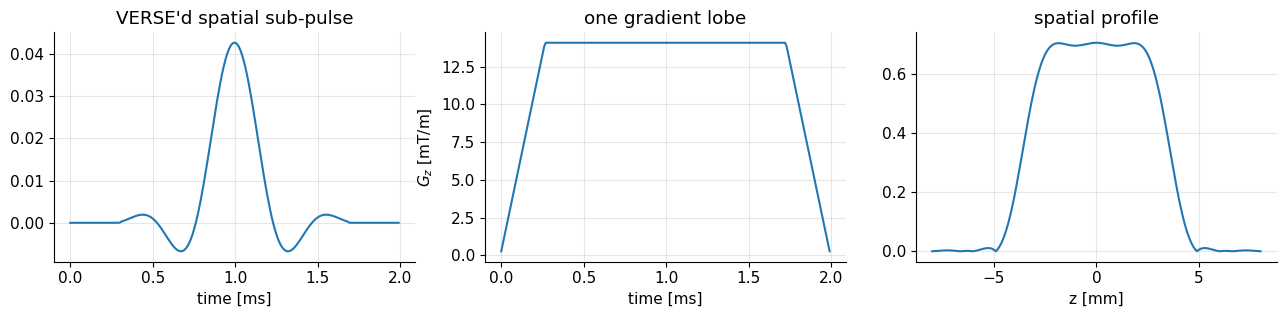

gradient amplitude 14.1 mT/m, ramp 270 us (limit 40 mT/m, 150 T/m/s)


In [6]:
rf_spat = dzrf_st(N_spat, SBW)
g_amp = (SBW / DT) / (GB * dz)                                   # T/m
N_ramp = min(int(np.ceil(G_max / SR_max / dt)), N_lobe // 2)     # ramp samples (uses the full slew-rate budget)
ramp = (np.arange(N_ramp) + 0.5) / N_ramp
g1 = np.concatenate([ramp, np.ones(N_lobe - 2 * N_ramp), ramp[::-1]])    # normalized lobe shape
rf_spat_v = verse(g1, np.concatenate([np.zeros(int(np.floor(N_wait))), rf_spat, np.zeros(int(np.ceil(N_wait)))]))
rf_spat_v = np.nan_to_num(rf_spat_v)

# spatial profile of one sub-pulse (scaled to the full flip angle just for display)
ph = mt.GAMMA * g_amp * np.outer(g1, z) * dt
a, b = cayley_klein(rf_spat_v * (flip / rf_spat_v.sum()), ph)
fig, ax = plt.subplots(1, 3, figsize=(13, 3.3))
tl = np.arange(N_lobe) * dt * 1e3
ax[0].plot(tl, rf_spat_v.real); ax[0].set_title("VERSE'd spatial sub-pulse"); ax[0].set_xlabel("time [ms]")
ax[1].plot(tl, g_amp * g1 * 1e3); ax[1].set_ylabel("$G_z$ [mT/m]"); ax[1].set_xlabel("time [ms]"); ax[1].set_title("one gradient lobe")
ax[2].plot(z * 1e3, np.abs(mxy_from_ck(a, b))); ax[2].set_xlabel("z [mm]"); ax[2].set_title("spatial profile")
plt.tight_layout(); plt.show()
print(f"gradient amplitude {g_amp*1e3:.1f} mT/m, ramp {N_ramp*dt*1e6:.0f} us (limit {G_max*1e3:.0f} mT/m, {SR_max:.0f} T/m/s)")

**Interpretation.** The sub-pulse has its full amplitude only on the flat part and is stretched and shrunk on the ramps, yet the profile is a clean slab about 5 mm thick. VERSE is also used to **reduce SAR** of ordinary pulses: lowering the gradient (and thus the RF amplitude) during the high-amplitude centre of a pulse reduces $\int|b_1|^2dt$ ([B6](B6_MRI_Safety.ipynb)).

### 2.4 Step 3: combine envelope and sub-pulses

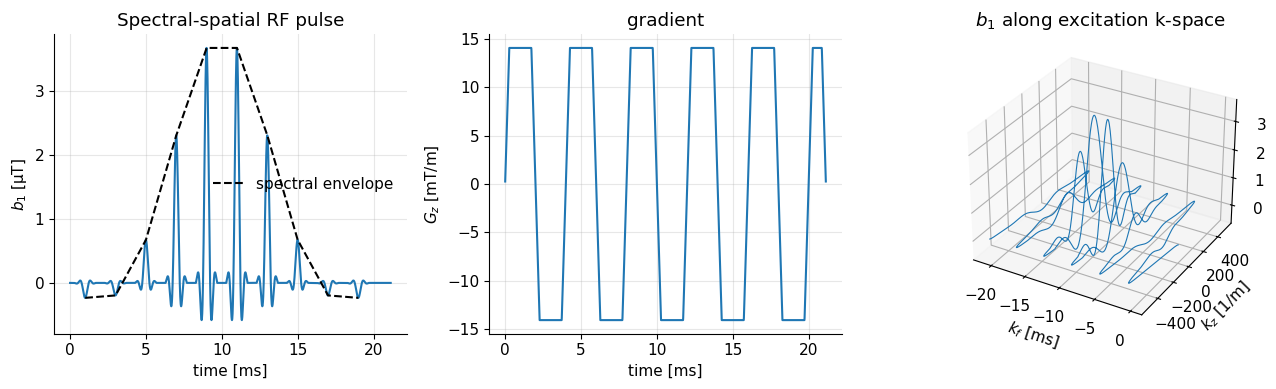

total duration 21.1 ms, peak B1 = 3.7 uT, k_z at end = -0.00 1/m


In [7]:
rf = np.concatenate([rf_spat_v * rf_spec[k] for k in range(N_spec)])           # weight sub-pulses by the envelope
g = np.concatenate([(1 if (k + 1) % 2 else -1) * g_amp * g1 for k in range(N_spec)])   # +,-,+,- ... lobes
N_rw = int(round((N_lobe - N_ramp) / 2 + N_ramp))
g_rw = np.concatenate([ramp, np.ones(N_rw - 2 * N_ramp), ramp[::-1]])
last_sign = 1 if N_spec % 2 else -1                    # sign of the last lobe
g = np.concatenate([g, -last_sign * g_amp * g_rw])     # rewinder: opposite polarity, ~half a lobe
rf = np.concatenate([rf, np.zeros(N_rw)])
rf = rf * (flip / rf.sum())                            # scale to the 45 deg flip angle (rad per sample)
b1 = rf / (mt.GAMMA * dt)                              # RF amplitude in tesla
t = np.arange(len(rf)) * dt
kz = GB * dt * (np.cumsum(g) - np.sum(g))              # k_z(t) = -gamma_bar * remaining gradient area
kf = t - t[-1]

fig = plt.figure(figsize=(13, 4))
ax1 = fig.add_subplot(1, 3, 1); ax1.plot(t * 1e3, b1.real * 1e6); ax1.set_xlabel("time [ms]"); ax1.set_ylabel(r"$b_1$ [µT]")
ax1.plot((np.arange(N_spec) + 0.5) * DT * 1e3, rf_spec / rf_spec.max() * b1.real.max() * 1e6, "k--", label="spectral envelope")
ax1.legend(); ax1.set_title("Spectral-spatial RF pulse")
ax2 = fig.add_subplot(1, 3, 2); ax2.plot(t * 1e3, g * 1e3); ax2.set_xlabel("time [ms]"); ax2.set_ylabel("$G_z$ [mT/m]")
ax2.set_title("gradient")
ax3 = fig.add_subplot(1, 3, 3, projection="3d"); ax3.plot(kf * 1e3, kz, b1.real * 1e6, lw=0.8)
ax3.set_xlabel("$k_f$ [ms]"); ax3.set_ylabel("$k_z$ [1/m]"); ax3.set_zlabel("$b_1$ [µT]"); ax3.set_title("$b_1$ along excitation k-space")
plt.tight_layout(); plt.show()
print(f"total duration {t[-1]*1e3:.1f} ms, peak B1 = {np.abs(b1).max()*1e6:.1f} uT, k_z at end = {kz[-1]:.2f} 1/m")

**Interpretation.** The RF consists of 10 sub-pulses whose amplitudes follow the spectral envelope (dashed). In excitation k-space (right), every sweep along $k_z$ deposits a spatial sub-pulse, and the sweeps are stacked along $k_f$ with weights given by the spectral pulse: a separable 2D weighting $H_f(k_f)H_z(k_z)$. The trajectory ends at $k_z = 0$ thanks to the rewinder.

## 3. The 2D spectral-spatial profile

Now simulate the full pulse for a grid of positions $z$ and frequencies $f$. Each spin sees, per raster step, the precession angle $\gamma G_z(t) z\,\Delta t + 2\pi f\,\Delta t$.

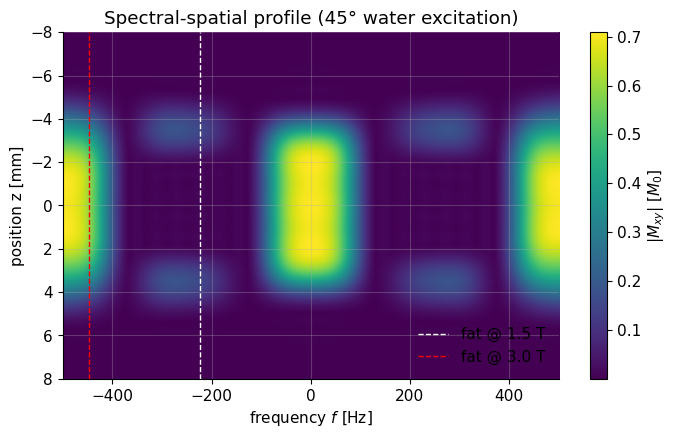

max |difference| spinor vs mt.bloch_simulate on the z = 0 line: 0.0


In [8]:
Z, F = np.meshgrid(z, df, indexing="ij")
phase = mt.GAMMA * np.outer(g, Z.ravel()) * dt + 2 * np.pi * F.ravel()[None, :] * dt
a, b = cayley_klein(rf, phase)
mxy2d = mxy_from_ck(a, b).reshape(Z.shape)

plt.figure(figsize=(8, 4.5))
plt.imshow(np.abs(mxy2d), extent=[df[0], df[-1], z[-1] * 1e3, z[0] * 1e3], aspect="auto", cmap="viridis")
plt.colorbar(label="$|M_{xy}|$ [$M_0$]")
for B0, c in ((1.5, "w"), (3.0, "r")):
    plt.axvline(mt.ppm_to_hz(mt.FAT_SHIFT_PPM, B0), color=c, ls="--", lw=1, label=f"fat @ {B0} T")
plt.xlabel("frequency $f$ [Hz]"); plt.ylabel("position z [mm]"); plt.legend(loc="lower right")
plt.title("Spectral-spatial profile (45° water excitation)"); plt.show()

# sanity check of the spinor simulator against the step-by-step Bloch simulator (z = 0 line)
iz0 = np.argmin(np.abs(z))
_, M = mt.bloch_simulate(B1=b1, dt=dt, df=df, return_all=False)
print("max |difference| spinor vs mt.bloch_simulate on the z = 0 line:", np.abs(M[:, 0] + 1j * M[:, 1] - mxy2d[iz0]).max().round(6))

**Interpretation.** Water (around 0 Hz) is excited only inside the 5 mm slice, while fat at 1.5 T (white dashed line) receives almost no excitation: no fat signal, so no fat chemical-shift artifact in EPI. Two features are worth noticing:

* the **spectral replicas** at ±500 Hz (from sampling the envelope every $\Delta T$);
* weaker **"ghost" lobes at ±250 Hz near the slice edges.** An off-resonant spin is excited as if it sat at a slightly shifted position, $\delta z = f/(\bar\gamma G_z)$, and the shift has opposite sign on positive and negative lobes. The odd and even sub-pulses therefore disagree at the slice edges, and this odd/even mismatch is sampled only every $2\Delta T$, so it replicates every $1/(2\Delta T) = 250$ Hz. This is the excitation analogue of the EPI Nyquist ghost. Fat at 1.5 T (−224 Hz) lies close to these ghosts at the slice edges. This is one reason some designs use **flyback** gradients (excite only on lobes of one polarity) at the cost of longer pulses.

The spinor result agrees with the step-by-step Bloch simulator, confirming the simulation.

> **TODO (polish):** Add a flyback (unipolar) design for comparison, and a Bloch-simulated EPI slice with and without the spectral-spatial pulse showing the removed fat shift.

## 4. Engineering reality: choosing $\Delta T$ for the field strength

Because the spectral profile repeats every $1/\Delta T$, the sub-pulse spacing must be chosen so that **fat falls into a stopband, not onto a replica**. A good choice puts fat halfway between the water passband at 0 Hz and its first replica at $-1/\Delta T$:

$$\Delta f_{fat} \approx -\frac{1}{2\,\Delta T} \quad\Rightarrow\quad \Delta T \approx \frac{1}{2\,|\Delta f_{fat}|}$$

In [9]:
for B0 in (1.5, 3.0, 7.0):
    dff = abs(mt.ppm_to_hz(mt.FAT_SHIFT_PPM, B0))
    DT_opt = 1 / (2 * dff)
    G_need = (SBW / DT_opt) / (GB * dz)
    print(f"B0 = {B0}: fat at -{dff:4.0f} Hz -> DT ~ {DT_opt*1e3:4.2f} ms; spatial lobe then needs G ~ {G_need*1e3:5.1f} mT/m "
          f"for a {dz*1e3:.0f} mm slice (SBW = {SBW})")

B0 = 1.5: fat at - 224 Hz -> DT ~ 2.24 ms; spatial lobe then needs G ~  12.6 mT/m for a 5 mm slice (SBW = 6)
B0 = 3.0: fat at - 447 Hz -> DT ~ 1.12 ms; spatial lobe then needs G ~  25.2 mT/m for a 5 mm slice (SBW = 6)
B0 = 7.0: fat at -1043 Hz -> DT ~ 0.48 ms; spatial lobe then needs G ~  58.8 mT/m for a 5 mm slice (SBW = 6)


**Interpretation.** At 1.5 T the original's 2 ms lobes work. At 3 T the lobes must be about twice as short (≈1.1 ms), so the same slice needs about twice the gradient amplitude **and** the ramps take a larger fraction of each lobe. At 7 T the required gradients approach or exceed hardware and nerve-stimulation limits. Practical 3 T and 7 T designs therefore accept thicker slices, lower spatial TBW, use flyback/VERSE tricks, or place fat on a deliberately chosen *other* stopband. Spectral-spatial design is a balancing act between **gradient performance, slice thickness, spectral selectivity and pulse duration**, a nice example of how MRI hardware limits shape the physics you can use.

Watch how the transverse magnetization evolves during a spectral-spatial RF pulse (animation from the original book, made with SpinBench):

![spectral_spatial_RF_animation.gif](../images/spectral_spatial_RF_animation.gif)

## Key takeaways

* In the small-tip regime, $M_{xy}(z,f)$ is approximately the 2D Fourier transform of the RF energy along $(k_f, k_z)$; **time acts as the spectral k-space axis** ($k_f = t - T$).
* An **oscillating gradient** sweeps $k_z$ back and forth, giving an EPI-like trajectory; a **rewinder** returns to $k_z = 0$.
* With a separable target, the pulse is **spectral envelope × spatial sub-pulses**: two 1D designs combined.
* **VERSE** lets sub-pulses play on the gradient ramps (and is a general SAR-reduction tool).
* Sampling the envelope every $\Delta T$ makes the spectral profile **periodic with $1/\Delta T$**, so $\Delta T$ must be matched to the fat frequency, i.e. to $B_0$.
* At higher fields, shorter lobes demand stronger gradients: a hardware trade-off between slice thickness, selectivity and duration.

## Check your understanding

1. Why does *time* act like a k-space coordinate for the spectral dimension?

<details><summary>Answer</summary>

A spin with off-resonance $f$ precesses by $2\pi f$ per second in the rotating frame. RF deposited at time $t$ has $T-t$ seconds of free precession left, so it acquires phase $-2\pi f (T-t) = 2\pi f\,k_f$ with $k_f = t - T$. This has the same form as the spatial phase $2\pi k_z z$, so $f$ plays the role of a position and $k_f$ the role of a k-space coordinate that advances linearly with time.

</details>

2. With $N_{spec}=10$ sub-pulses over 20 ms, how often does the spectral profile repeat? What would go wrong at 3 T?

<details><summary>Answer</summary>

$\Delta T = 2$ ms, so it repeats every $1/\Delta T = 500$ Hz. At 3 T fat is at about −447 Hz, close to the replica of the water passband at −500 Hz, so fat would be partly **excited** instead of suppressed. The lobe spacing must be reduced to about 1.1 ms.

</details>

3. What does VERSE change and what does it keep the same?

<details><summary>Answer</summary>

It changes the time course of the RF and gradient (RF stretched and reduced where the gradient is weak, e.g. on ramps). It keeps the distribution of RF energy along excitation k-space, and therefore (in the small-tip regime) the excitation profile and flip angle, the same.

</details>

4. Why is a rewinder lobe needed at the end, and why does it have about half the area of a lobe?

<details><summary>Answer</summary>

Each sub-pulse is centred in its lobe, so after the last lobe the trajectory is still half a lobe away from $k_z=0$. This leaves a linear phase across the slice (signal loss after integration over the voxel). A lobe of opposite polarity with half the area moves $k_z$ back to 0, exactly as the slice-select rewinder in [E2](E2_Slice_Selection.ipynb).

</details>

---
*Adapted and extended from P. Larson, "Principles of MRI" (MIT License), chapter "Spectral-Spatial RF Pulses". Changes: Octave code ported to Python (own SLR small-tip designer, spinor simulator and VERSE), units converted to SI and the original's unit comments corrected, excitation k-space derivation, spectral replica analysis and field-strength design rule added.*